## **Eidible or Posioneous? A Mushroom Classification Model using Descion Tree**

## **Dataset Overview**

- Taget variable: Class --> edible(e) or posionous(p)
- Features: 22 categorical variables describing:
- cap shape, color,odour
- Gill size, attachment,spacing
- Stalk dimensions,color
- Habitat,population


In [2]:
import pandas as pd

In [3]:
df = pd.read_csv(r'c:\Users\LENOVO\Downloads\mushrooms.csv')
df.head()

,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g


In [4]:
df.isnull().sum()

class                       0
cap-shape                   0
cap-surface                 0
cap-color                   0
bruises                     0
odor                        0
gill-attachment             0
gill-spacing                0
gill-size                   0
gill-color                  0
stalk-shape                 0
stalk-root                  0
stalk-surface-above-ring    0
stalk-surface-below-ring    0
stalk-color-above-ring      0
stalk-color-below-ring      0
veil-type                   0
veil-color                  0
ring-number                 0
ring-type                   0
spore-print-color           0
population                  0
habitat                     0
dtype: int64

In [5]:
df['class'].unique() # Check its binary or multilevel class

array(['p', 'e'], dtype=object)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8124 entries, 0 to 8123
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   class                     8124 non-null   object
 1   cap-shape                 8124 non-null   object
 2   cap-surface               8124 non-null   object
 3   cap-color                 8124 non-null   object
 4   bruises                   8124 non-null   object
 5   odor                      8124 non-null   object
 6   gill-attachment           8124 non-null   object
 7   gill-spacing              8124 non-null   object
 8   gill-size                 8124 non-null   object
 9   gill-color                8124 non-null   object
 10  stalk-shape               8124 non-null   object
 11  stalk-root                8124 non-null   object
 12  stalk-surface-above-ring  8124 non-null   object
 13  stalk-surface-below-ring  8124 non-null   object
 14  stalk-color-above-ring  

In [7]:
df.shape

(8124, 23)

<Axes: xlabel='class', ylabel='Count'>

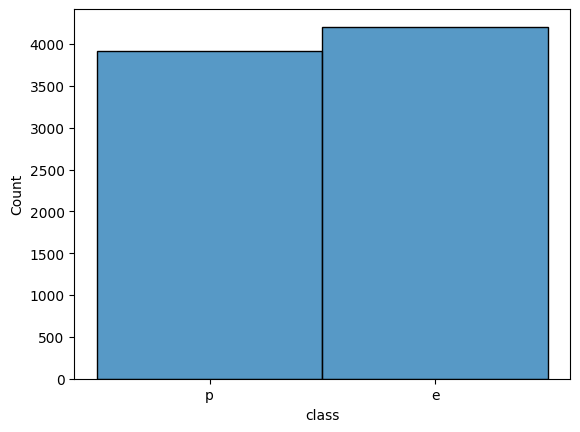

In [8]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.histplot(df['class'])

In [9]:
#Inferance:
# There is approx balance data

## **Seperating Features and Target**

In [10]:
x = df.drop('class',axis=1)
y = df['class']

In [11]:
x.head()

,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,stalk-shape,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,x,s,n,t,p,f,c,n,k,e,...,s,w,w,p,w,o,p,k,s,u
1,x,s,y,t,a,f,c,b,k,e,...,s,w,w,p,w,o,p,n,n,g
2,b,s,w,t,l,f,c,b,n,e,...,s,w,w,p,w,o,p,n,n,m
3,x,y,w,t,p,f,c,n,n,e,...,s,w,w,p,w,o,p,k,s,u
4,x,s,g,f,n,f,w,b,k,t,...,s,w,w,p,w,o,e,n,a,g


In [12]:
y.head()

0    p
1    e
2    e
3    p
4    e
Name: class, dtype: object

## **Create Dummy Variable for our Categorical Data**

In [13]:
x = pd.get_dummies(x).astype(int)
x.head()

,cap-shape_b,cap-shape_c,cap-shape_f,cap-shape_k,cap-shape_s,cap-shape_x,cap-surface_f,cap-surface_g,cap-surface_s,cap-surface_y,...,population_s,population_v,population_y,habitat_d,habitat_g,habitat_l,habitat_m,habitat_p,habitat_u,habitat_w
0,0,0,0,0,0,1,0,0,1,0,...,1,0,0,0,0,0,0,0,1,0
1,0,0,0,0,0,1,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0
2,1,0,0,0,0,0,0,0,1,0,...,0,0,0,0,0,0,1,0,0,0
3,0,0,0,0,0,1,0,0,0,1,...,1,0,0,0,0,0,0,0,1,0
4,0,0,0,0,0,1,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0


In [14]:
x.shape

(8124, 117)

In [15]:
# Labelencoder
# One Hot Encoder: 0,1 arrary
# OridinalEncoder : Encode Categorical features using oridnal enconding scheme

In [16]:
from sklearn.preprocessing import LabelEncoder
label_y = LabelEncoder()
y = label_y.fit_transform(y)
print(y)

[1 0 0 ... 0 1 0]


## **Splitting Dataset to training and test data 80% -20%**

In [17]:
from sklearn.model_selection import train_test_split

In [18]:
x_train , x_test , y_train , y_test = train_test_split(x,y,test_size=0.2,random_state=42)

In [19]:
x_train.shape,x_test.shape

((6499, 117), (1625, 117))

In [20]:
y_train.shape , y_test.shape

((6499,), (1625,))

## **Decision Tree Creation**

In [21]:
from sklearn.tree import DecisionTreeClassifier # to train model 
from sklearn import tree # to plot
from sklearn.metrics import accuracy_score # To check overfitting and underfitting

## **Creation of Decision Trree using Gini Index**

In [22]:
## Creating model using gini
clf_gini = DecisionTreeClassifier(criterion='gini',max_depth=3,random_state=0)

# fit the model 
clf_gini.fit(x_train,y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current nod

In [23]:
x_train.head()

,cap-shape_b,cap-shape_c,cap-shape_f,cap-shape_k,cap-shape_s,cap-shape_x,cap-surface_f,cap-surface_g,cap-surface_s,cap-surface_y,...,population_s,population_v,population_y,habitat_d,habitat_g,habitat_l,habitat_m,habitat_p,habitat_u,habitat_w
7873,0,0,0,1,0,0,0,0,1,0,...,0,1,0,1,0,0,0,0,0,0
6515,0,0,0,0,0,1,0,0,1,0,...,0,1,0,0,0,0,0,1,0,0
6141,0,0,1,0,0,0,0,0,0,1,...,0,1,0,0,0,1,0,0,0,0
2764,0,0,1,0,0,0,1,0,0,0,...,0,1,0,1,0,0,0,0,0,0
438,1,0,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,1,0,0,0


In [24]:
# Predict the values
y_pred_gini = clf_gini.predict(x_test)
y_pred_gini 

array([0, 1, 1, ..., 1, 1, 1], shape=(1625,))

In [25]:
y_pred_train_gini = clf_gini.predict(x_train)
y_pred_train_gini


array([1, 1, 1, ..., 0, 1, 0], shape=(6499,))

## **Checking Overfitting**

overfitting occures when accuarcy for training set is high and test set is very low comparing to training set.


In [26]:
# Determine the accuarcy score
print('Model Acccuary Score With Creation Gini Index: {0:0.4f}'.format(accuracy_score(y_test,y_pred_gini)))

# Accuaracy score for training set
print('Training-Set accuarcy score: {0:0.4f}'.format(accuracy_score(y_train,y_pred_train_gini)))

Model Acccuary Score With Creation Gini Index: 0.9809
Training-Set accuarcy score: 0.9863


In [27]:
x_train.columns

Index(['cap-shape_b', 'cap-shape_c', 'cap-shape_f', 'cap-shape_k',
       'cap-shape_s', 'cap-shape_x', 'cap-surface_f', 'cap-surface_g',
       'cap-surface_s', 'cap-surface_y',
       ...
       'population_s', 'population_v', 'population_y', 'habitat_d',
       'habitat_g', 'habitat_l', 'habitat_m', 'habitat_p', 'habitat_u',
       'habitat_w'],
      dtype='object', length=117)

In [28]:
features = x_train.columns

[Text(0.5769230769230769, 0.875, 'odor_n <= 0.5\ngini = 0.499\nsamples = 6499\nvalue = [3365, 3134]\nclass = edible'),
 Text(0.3076923076923077, 0.625, 'stalk-root_c <= 0.5\ngini = 0.284\nsamples = 3666\nvalue = [627, 3039]\nclass = poisonous'),
 Text(0.4423076923076923, 0.75, 'True  '),
 Text(0.15384615384615385, 0.375, 'stalk-root_r <= 0.5\ngini = 0.124\nsamples = 3221\nvalue = [213.0, 3008.0]\nclass = poisonous'),
 Text(0.07692307692307693, 0.125, 'gini = 0.044\nsamples = 3077\nvalue = [69, 3008]\nclass = poisonous'),
 Text(0.23076923076923078, 0.125, 'gini = 0.0\nsamples = 144\nvalue = [144, 0]\nclass = edible'),
 Text(0.46153846153846156, 0.375, 'ring-type_p <= 0.5\ngini = 0.13\nsamples = 445\nvalue = [414.0, 31.0]\nclass = edible'),
 Text(0.38461538461538464, 0.125, 'gini = 0.0\nsamples = 31\nvalue = [0, 31]\nclass = poisonous'),
 Text(0.5384615384615384, 0.125, 'gini = 0.0\nsamples = 414\nvalue = [414, 0]\nclass = edible'),
 Text(0.8461538461538461, 0.625, 'spore-print-color_r <

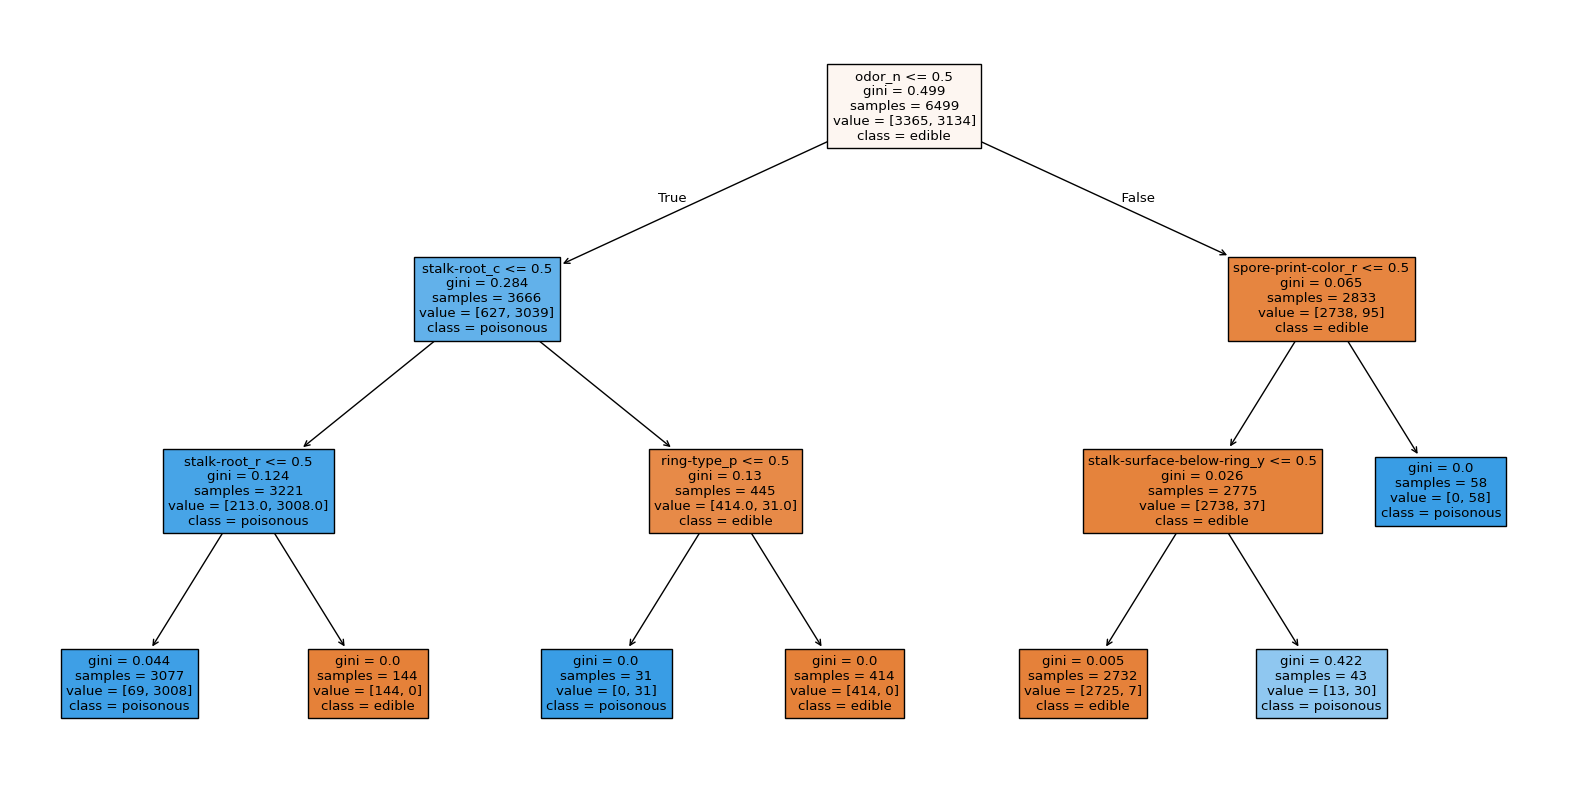

In [39]:
from sklearn.tree import plot_tree
plt.figure(figsize=(20,10))
class_names = ['edible','poisonous']
plot_tree(clf_gini,class_names=class_names,filled=True,feature_names=features)

## **Creation of Decision tree using with entropy**

In [30]:
clf_en = DecisionTreeClassifier(criterion='entropy',max_depth=3,random_state=42)
# Fit the model 
clf_en.fit(x_train,y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",42
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current

[Text(0.5555555555555556, 0.875, 'odor_n <= 0.5\nentropy = 0.999\nsamples = 6499\nvalue = [3365, 3134]'),
 Text(0.3333333333333333, 0.625, 'bruises_f <= 0.5\nentropy = 0.66\nsamples = 3666\nvalue = [627, 3039]'),
 Text(0.4444444444444444, 0.75, 'True  '),
 Text(0.2222222222222222, 0.375, 'stalk-root_c <= 0.5\nentropy = 0.974\nsamples = 1054\nvalue = [627, 427]'),
 Text(0.1111111111111111, 0.125, 'entropy = 0.918\nsamples = 640\nvalue = [213, 427]'),
 Text(0.3333333333333333, 0.125, 'entropy = 0.0\nsamples = 414\nvalue = [414, 0]'),
 Text(0.4444444444444444, 0.375, 'entropy = 0.0\nsamples = 2612\nvalue = [0, 2612]'),
 Text(0.7777777777777778, 0.625, 'spore-print-color_r <= 0.5\nentropy = 0.212\nsamples = 2833\nvalue = [2738, 95]'),
 Text(0.6666666666666667, 0.75, '  False'),
 Text(0.6666666666666666, 0.375, 'stalk-surface-below-ring_y <= 0.5\nentropy = 0.102\nsamples = 2775\nvalue = [2738, 37]'),
 Text(0.5555555555555556, 0.125, 'entropy = 0.026\nsamples = 2732\nvalue = [2725, 7]'),
 Te

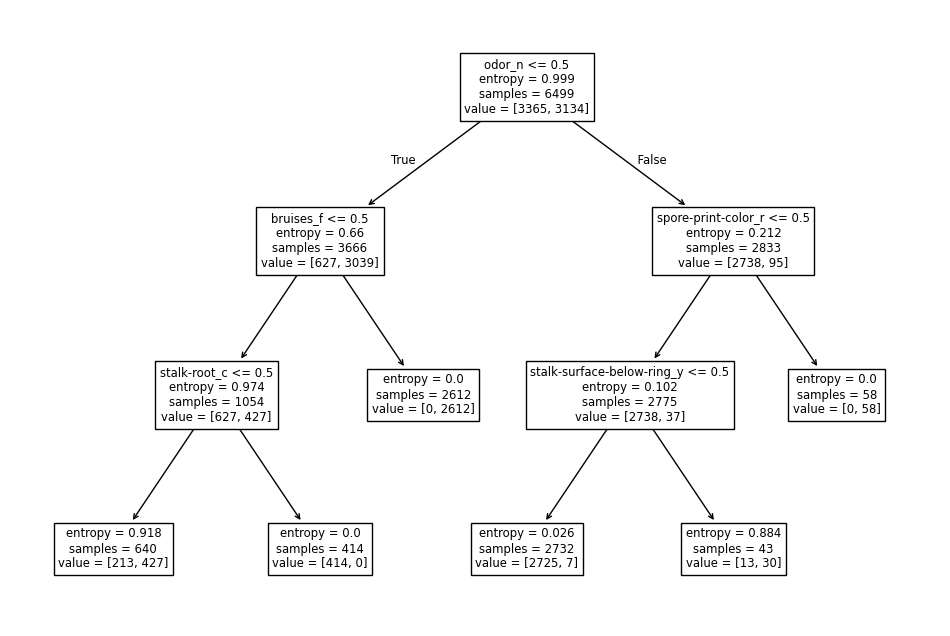

In [31]:
plt.figure(figsize=(12,8))
tree.plot_tree(clf_en.fit(x_train,y_train),feature_names=features)

In [32]:
# Predict the values 
y_pred_en = clf_en.predict(x_test)

In [33]:
# Predict the values using x_train for accuarcy comparision 
y_pred_train_en = clf_en.predict((x_train))

## **Check Overfitting**

In [34]:
print('Model accuaracy score with creation entropy: {0:0.4f}'.format(accuracy_score(y_test,y_pred_en)))
print('Traning-set accuaracy score: {0:0.4f}'.format(accuracy_score(y_train,y_pred_train_en)))

Model accuaracy score with creation entropy: 0.9514
Traning-set accuaracy score: 0.9641


## **Confusion Matrix**

In [35]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from sklearn.metrics import f1_score

In [36]:
cm= confusion_matrix(y_test,y_pred_en)
print('confusion_matrix\n',cm)

confusion_matrix
 [[765  78]
 [  1 781]]


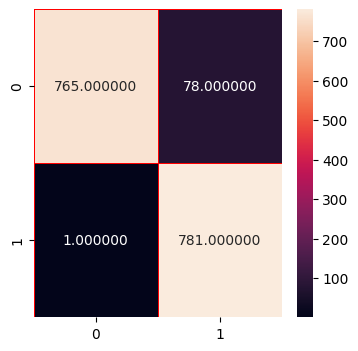

In [37]:
f,ax = plt.subplots(figsize=(4,4))
sns.heatmap(cm,annot=True,linecolor='red',linewidths=0.5,fmt ='0f',ax = ax)
plt.show()

In [38]:
from sklearn.metrics import classification_report
print(classification_report(y_test,y_pred_en))

              precision    recall  f1-score   support

           0       1.00      0.91      0.95       843
           1       0.91      1.00      0.95       782

    accuracy                           0.95      1625
   macro avg       0.95      0.95      0.95      1625
weighted avg       0.96      0.95      0.95      1625

